# Class Cardinality Counter
  ## SUBS
  ### Exact Count
  ### LogLog Counter
  

In [ ]:
import random
import pylab as plt
import hashlib
import numpy as np
import time
from sys import getsizeof
from scipy.stats import sem
from scipy.cluster.hierarchy import DisjointSet

In [ ]:
class CardinalityCounter:
  def add(self,data_item):
    pass
  
  def count(self):
    pass

In [ ]:
class ExactCounter(CardinalityCounter):

  def __init__(self):
    self.dictionary_value_to_count = {}
  def add(self,item):
    if item not in self.dictionary_value_to_count.keys():
      self.dictionary_value_to_count[item] = 1
  def count(self):
    return len(self.dictionary_value_to_count)
  def get_size(self):
    return getsizeof(self.dictionary_value_to_count)

In [ ]:
test = ExactCounter()
test.add('a')
test.add('b')
test.add('b')
assert test.count() == 2

In [ ]:
def hash_new(key):
  key = repr(key).encode()
  return (int(hashlib.md5(key).hexdigest(),16)) % (2**64)

class LogLogCounter(CardinalityCounter):
  def __init__(self,k):
    self.ranks_list = [0 for i in range(2**k)]
    self.k = k
    self.m = 2**k
  def get_binary_hash(self,data_item):
    hashed_value = hash_new(str(data_item))
    hashed_value = bin(hashed_value)
    #print(hashed_value)
    hashed_value = hashed_value[2::]
    values_bin = ["0","1"]
    
    if hashed_value[0] not in values_bin:
      hashed_value = hashed_value[1::]
    
    if len(hashed_value) != 64:
      length_string = "0" * (64 - len(hashed_value))
      hashed_value = length_string + hashed_value
    return hashed_value

  def count_continuous_zeros(self, binary):
    binary = binary[::-1]
    # Count zeros
    rank = 1
    for i in binary:
      if i == '1':
        break
      else:
        rank += 1
    return rank

  def ranks_set(self,data_item):
    binary_rep = self.get_binary_hash(data_item)
    #print(binary_rep)
    index = binary_rep[0:self.k]
    index = int(index,2)
    # Count continuous zeros from the right
    rank = binary_rep[self.k:]
    rank = self.count_continuous_zeros(rank)

    #print(index,rank)
    if self.ranks_list[index] < rank:
      self.ranks_list[index] = rank

  def count(self,alpha):
    #sum estimators
    sums = sum(self.ranks_list)
    sums = sums / self.m
    return round(alpha * (self.m) * (2**sums))
  
  def get_size(self):
    return getsizeof(self.ranks_set)

  def merge(self,other_ranks):
    for i in range(len(other_ranks)):
      if other_ranks[i] > self.ranks_list[i]:
        self.ranks_list[i] = other_ranks[i]

In [ ]:
g = LogLogCounter(3)
g.ranks_set('apple')
g.ranks_set('sounders')
print(g.ranks_list)
a = LogLogCounter(3)
a.ranks_set('c')
a.ranks_set('a')
a.ranks_set('d')
print(a.ranks_list)
g.merge(a.ranks_list)
assert g.ranks_list == [3,0,3,0,1,0,0,0]

[0, 0, 1, 0, 1, 0, 0, 0]
[3, 0, 3, 0, 0, 0, 0, 0]


# Experiments

In [ ]:
def generate_random_string():
  return str(random.randint(0,2**64))

In [ ]:
def loglog_trial_one(size,k,alpha = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  exact_class = ExactCounter()
  # Generate and add in
  for i in range(size):
    item = generate_random_string()
    exact_class.add(item)
    estimated_class.ranks_set(item)
  if get_size == True:
    size = estimated_class.get_size()
    size_2 = exact_class.get_size()
    return size , size_2
  else:
    return (exact_class.count(),estimated_class.count(alpha))

In [ ]:
def loglog_trial_time(size,k,alpha = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  # Generate and add in
  for i in range(size):
    item = generate_random_string()
    estimated_class.ranks_set(item)
  return estimated_class.count(alpha)

In [ ]:
def exact_one_trial(size,get_size=False):
  exact_class = ExactCounter()
  for i in range(size):
    exact_class.add(generate_random_string())
  
  if get_size == True:
    return size
  return exact_class.count()

#Time Comparison

In [ ]:
def time_compare(size,k,alpha):
  time_1 = time.time()
  count = loglog_trial_time(size,k,alpha)
  time_2 = time.time()
  time_3 = time.time()
  count = exact_one_trial(size)
  time_4 = time.time()
  return (time_2-time_1,time_4-time_3)

In [ ]:
def time_comparison(k,alpha,min,max,interval):
  x = []
  y = []
  y_2 = []
  for i in range(min,max,interval):
    trial = time_compare(i,k,alpha)
    y.append(trial[0])
    y_2.append(trial[1])
    x.append(i)
  plt.plot(x,y,color='r',label = "Estimated Cardinality Time")
  plt.plot(x,y_2,color='g',label = "Real Cardinality Time")
  plt.legend()
  plt.title("Time Comparison: Real vs. Estimated Cardinality")
  plt.xlabel("Dataset Size")
  plt.ylabel("Time in Seconds")
  average_est = sum(y)/len(y)
  average_real = sum(y_2)/len(y)
  #print(average_est,average_real)
  print("On Average The Estimation Saves " + str(round((average_real/average_est),3)) + " Times of Memory Space")

On Average The Estimation Saves 0.427 Times of Memory Space


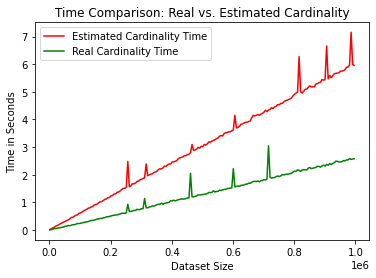

In [ ]:
time_comparison(16,0.3997429102087941,1000,1000000,5000)

On Average The Estimation Saves 0.435 Times of Memory Space


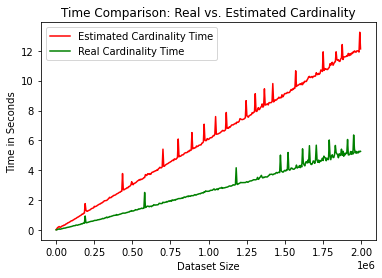

In [ ]:
time_comparison(16,0.3997429102087941,1000,2000000,5000)

# Size

In [ ]:
def size_comparison(k,alpha,min,max,interval):
  x = []
  y = []
  y_2 = []
  giga = 2**30
  for i in range(min,max,interval):
    trial = loglog_trial_one(i,k,alpha,True)
    y.append(trial[0]/2**30)
    y_2.append(trial[1]/2**30)
    x.append(i)
  plt.plot(x,y,color='r',label = "Estimated Cardinality Size")
  plt.plot(x,y_2,color='g',label = "Real Cardinality Size")
  plt.legend()
  plt.title("Size Comparison: Real vs. Estimated Cardinality")
  plt.xlabel("Data Items")
  plt.ylabel("Size in Gigabytes")
  plt.yscale('log')
  average_est = sum(y)/len(y)
  average_real = sum(y_2)/len(y)
  #print(average_est,average_real)
  print("On Average The Estimation Saves " + str(round((average_real/average_est),3)) + " Times of Memory Space")

On Average The Estimation Saves 310533.202 Times of Memory Space


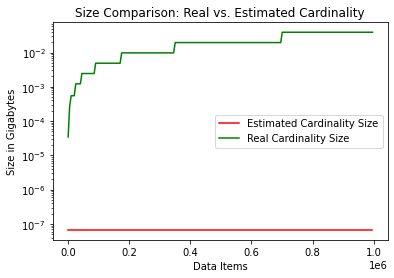

In [ ]:
size_comparison(16,0.3997429102087941,1000,1000000,5000)

On Average The Estimation Saves 621301.123 Times of Memory Space


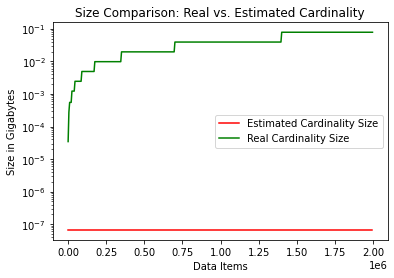

In [ ]:
size_comparison(16,0.3997429102087941,1000,2000000,5000)

# Running for Accuracy

In [ ]:
def plot_graph_loglog(k,interval,min,max,trials_per_size,alpha):
  x = []
  y = []
  x_line = [i for i in range(min,max,interval)]
  for size in range(min,max,interval):
    real = 0
    estimation = 0
    for trials in range(trials_per_size):
      tup = loglog_trial_one(size,k,alpha)
      real += tup[0]
      estimation += tup[1]
    real = real / trials_per_size
    estimation = estimation / trials_per_size
    #print(real,estimation)
    #print(real,estimation)
    x.append(real)
    y.append(estimation)
  plt.plot(x,y,color = 'r',label = "Estimated Cardinality")
  plt.plot(x_line,x_line, color = 'g', label = "Real Cardinality", linestyle = "dashed")
  plt.ylabel("Estimated Dataset Cardinality " + "Alpha:" +str(alpha))
  plt.title("Unique Element Set Cardinality: Real vs. Estimation"+" M =" + str(2**k))
  plt.legend()
  plt.ticklabel_format(style='plain')
  plt.show()
  a,b = np.polyfit(x,y,1)
  print('Correcting Alpha =', (1/a))
  print("Standard Error = "+str(round(sem(y),3)))
  average_of_mean = sum(x_line)/len(y)
  print("Error Percentage = "+str(round((sem(y)/average_of_mean)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))

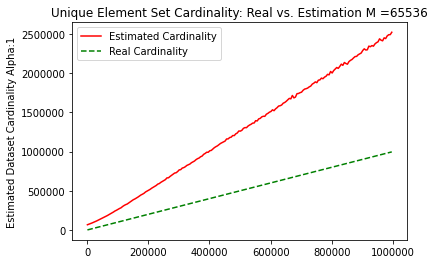

Correcting Alpha = 0.3997429102087941
Standard Error = 51198.427
Error Percentage = 10.27%


In [ ]:
plot_graph_loglog(16,5000,1000,1000000,1,1)

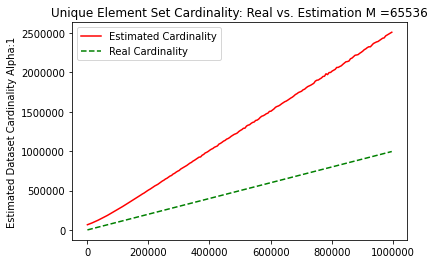

Correcting Alpha = 0.39988661031661915
Standard Error = 51177.591
Error Percentage = 10.266%


In [ ]:
plot_graph_loglog(16,5000,1000,1000000,3 ,1)

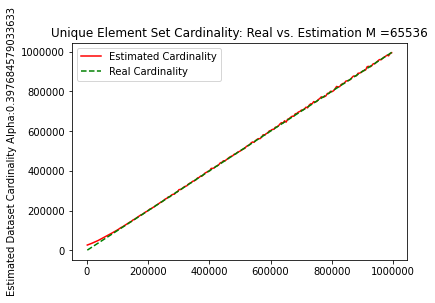

Correcting Alpha = 1.005926553792693
Standard Error = 20345.064
Error Percentage = 4.081%


In [ ]:
plot_graph_loglog(16,5000,1000,1000000,1,0.397684579033633)

In [ ]:
 def loglog_v_exact_accuracy_comparison(size,k,alpha):
  count_2 = loglog_trial_one(size,k,alpha)
  listed = [count_2[0],count_2[1]]
  value = sem(listed)/count_2[0]
  return (100,100-value)

In [ ]:
def loglog_v_exact_accuracy_plot(k,alpha,min,max,interval,ymin,ymax,xmin,xmax):
  x = []
  y = []
  y_2 = []
  for i in range(min,max,interval):
    trial = loglog_v_exact_accuracy_comparison(i,k,alpha)
    y.append(trial[0])
    y_2.append(trial[1])
    x.append(i)
  plt.plot(x,y,color ='r',label = "Exact Counting")
  plt.plot(x,y_2, color = 'g',label= "Loglog Counting")
  plt.ticklabel_format(style='plain')
  plt.title("Loglog vs. Exact Counting Accuracy Comparison: Alpha = " + str(alpha))
  plt.xlabel("Dataset Size")
  plt.ylabel("Percentage Accuracy")
  plt.legend()
  plt.ylim(ymin,ymax)
  plt.xlim(xmin,xmax)
  plt.ticklabel_format(style='plain')

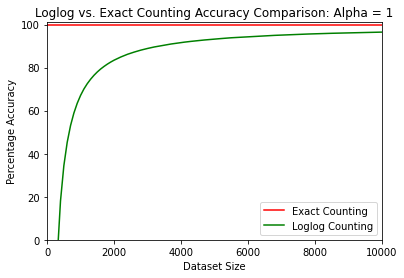

In [ ]:
loglog_v_exact_accuracy_plot(16,1,1,20000,100,0,101,0,10000)

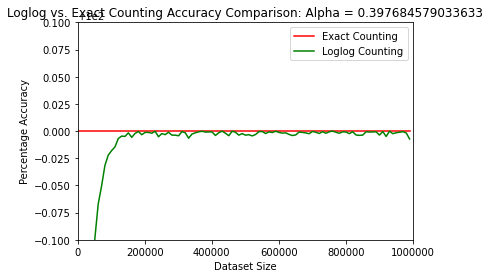

In [ ]:
loglog_v_exact_accuracy_plot(16,0.397684579033633,1000,1000000,10000,99.9,100.1,0,1000000)

In [ ]:
def loglog_trial_one_union(size,k,alpha = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  exact_class = ExactCounter()
  estimated_2 = LogLogCounter(k)
  # Generate and add in
  for i in range(size//2):
    item = generate_random_string()
    exact_class.add(item)
    estimated_class.ranks_set(item)
  for i in range(size//2):
    item = generate_random_string()
    exact_class.add(item)
    estimated_2.ranks_set(item)
  estimated_class.merge(estimated_2.ranks_list)
  if get_size == True:
    size = estimated_class.get_size()
    return size
  else:
    return (exact_class.count(),estimated_class.count(alpha))

In [ ]:
def plot_graph_loglog_merge(k,interval,min,max,trials_per_size,alpha):
  x = []
  y = []
  x_line = [i for i in range(min,max,interval)]
  for size in range(min,max,interval):
    real = 0
    estimation = 0
    for trials in range(trials_per_size):
      tup = loglog_trial_one_union(size,k,alpha)
      real += tup[0]
      estimation += tup[1]
    real = real / trials_per_size
    estimation = estimation / trials_per_size
    #print(real,estimation)
    #print(real,estimation)
    x.append(real)
    y.append(estimation)
  plt.plot(x,y,color = 'r',label = "Estimated Cardinality")
  plt.plot(x_line,x_line, color = 'g', label = "Real Cardinality", linestyle = "dashed")
  plt.ylabel("Estimated Dataset Cardinality With Union of Two Sets " + "Alpha:" +str(alpha))
  plt.title("Unique Element Set Cardinality: Real vs. Estimation"+" M =" + str(2**k))
  plt.legend()
  plt.ticklabel_format(style='plain')
  plt.show()
  a,b = np.polyfit(x,y,1)
  print('Correcting Alpha =', (1/a))
  print("Standard Error = "+str(round(sem(y),3)))
  average_of_mean = sum(x_line)/len(y)
  print("Error Percentage = "+str(round((sem(y)/average_of_mean)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))

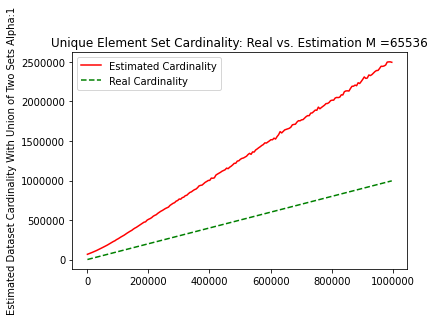

Correcting Alpha = 0.3998251155528454
Standard Error = 51188.07
Error Percentage = 10.268%


In [ ]:
plot_graph_loglog_merge(16,5000,1000,1000000,1,1)

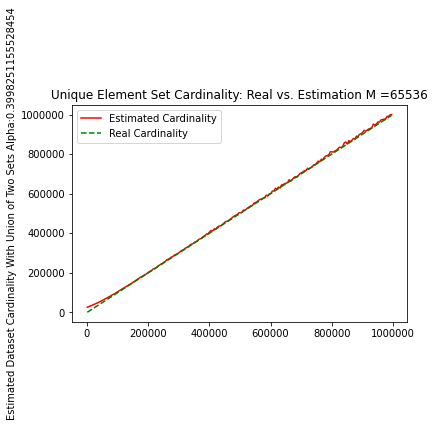

Correcting Alpha = 1.0003436191210686
Standard Error = 20459.043
Error Percentage = 4.104%


In [ ]:
plot_graph_loglog_merge(16,5000,1000,1000000,1,0.3998251155528454)

# Disjoint Set Experiment

In [ ]:
def get_two_disjoint_sets(size):
  set_1 = []
  dis = DisjointSet([])
  for i in range(size):
    dis.add(generate_random_string())
  set_1 = list(dis)
  return set(set_1[0:size//2]), set(set_1[size//2::])

In [ ]:
a,b = get_two_disjoint_sets(1000000)
a.isdisjoint(b)

True

In [ ]:
a,b = get_two_disjoint_sets(10000)
a.isdisjoint(b)

True

In [ ]:
def loglog_trial_one_disjoint_method_two_separate(size,k,alpha = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  estimated_class_2 = LogLogCounter(k)
  exact_class = ExactCounter()
  set_1 , set_2 = get_two_disjoint_sets(size)
  for i in set_1:
    estimated_class.ranks_set(i)
    exact_class.add(i)
  for i in set_2:
    estimated_class_2.ranks_set(i)
    exact_class.add(i)
  if get_size == True:
    size = estimated_class.get_size()
    return size
  else:
    total = estimated_class.count(alpha) + estimated_class_2.count(alpha)
    return (exact_class.count(),total)

In [ ]:
def loglog_trial_one_disjoint_method_combined(size,k,alpha = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  exact_class = ExactCounter()
  set_1 , set_2 = get_two_disjoint_sets(size)
  for i in set_1:
    estimated_class.ranks_set(i)
    exact_class.add(i)
  for i in set_2:
    estimated_class.ranks_set(i)
    exact_class.add(i)
  if get_size == True:
    size = estimated_class.get_size()
    return size
  else:
    return (exact_class.count(),estimated_class.count(alpha))

In [ ]:
def loglog_trial_one_disjoint_method(size,k,alpha = 1,alpha_2 = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  estimated_class_2 = LogLogCounter(k)
  estimated_class_3 = LogLogCounter(k)
  exact_class = ExactCounter()
  set_1 , set_2 = get_two_disjoint_sets(size)
  for i in set_1:
    estimated_class.ranks_set(i)
    estimated_class_3.ranks_set(i)
    exact_class.add(i)
  for i in set_2:
    estimated_class_2.ranks_set(i)
    estimated_class_3.ranks_set(i)
    exact_class.add(i)
  if get_size == True:
    size = estimated_class.get_size()
    return size
  else:
    total = estimated_class.count(alpha) + estimated_class_2.count(alpha)
    return [exact_class.count(),estimated_class_3.count(alpha_2),total]

In [ ]:
def plot_graph_loglog_disjoint(k,interval,min,max,trials_per_size,alpha, alpha_2):
  x = []
  y = []
  y_2 = []
  x_line = [i for i in range(min,max,interval)]
  for size in range(min,max,interval):
    real = 0
    estimation = 0
    estimation_2 = 0
    for trials in range(trials_per_size):
      tup = loglog_trial_one_disjoint_method(size,k,alpha,alpha_2)
      real += tup[0]
      estimation += tup[1]
      estimation_2 += tup[2]
    #print(real,estimation)
    #print(real,estimation)
    x.append(real)
    y.append(estimation)
    y_2.append(estimation_2)
  plt.plot(x,y,color = 'r',label = "Estimated Cardinality: Combined Method")
  plt.plot(x,y_2,color = 'b',label = "Estimated Cardinality: Separate Method")
  plt.plot(x_line,x_line, color = 'g', label = "Real Cardinality", linestyle = "dashed")
  plt.ylabel("Estimated Dataset Cardinality ")
  plt.title("Unique Element Set Cardinality: Real vs. Estimation"+" M =" + str(2**k))
  plt.legend()
  plt.ticklabel_format(style='plain')
  plt.show()
  a,b = np.polyfit(x,y,1)
  print("Combined Method Report")
  print('Correcting Alpha =', (1/a))
  print("Standard Error = "+str(round(sem(y),3)))
  average_of_mean = sum(x_line)/len(y)
  print("Error Percentage = "+str(round((sem(y)/average_of_mean)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))
  print(" ")
  a_2,b_2 = np.polyfit(x,y_2,1)
  print("Separate Method Report")
  print('Correcting Alpha =', (1/a_2))
  print("Standard Error = "+str(round(sem(y_2),3)))
  average_of_mean_2 = sum(x_line)/len(y_2)
  print("Error Percentage = "+str(round((sem(y_2)/average_of_mean_2)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))

In [ ]:
# Hypothesis is the combined method will be more better, separate method is based in smaller amounts which can lead to inaccuracy

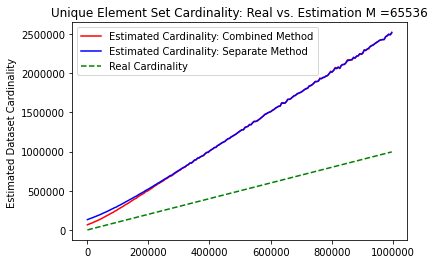

Combined Method Report
Correcting Alpha = 0.3994605152867176
Standard Error = 51234.471
Error Percentage = 10.278%
 
Separate Method Report
Correcting Alpha = 0.40739607588209065
Standard Error = 50251.598
Error Percentage = 10.081%


In [ ]:
plot_graph_loglog_disjoint(16,5000,1000,1000000,1,1,1)

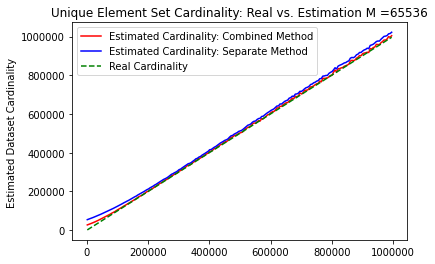

Combined Method Report
Correcting Alpha = 1.0002907718408691
Standard Error = 20459.946
Error Percentage = 4.104%
 
Separate Method Report
Correcting Alpha = 1.000847420581182
Standard Error = 20454.635
Error Percentage = 4.103%


In [ ]:
plot_graph_loglog_disjoint(16,5000,1000,1000000,1,0.40750723016868334,0.4000399474676889)

#Disjoint with Different Sizes


In [ ]:
def get_two_disjoint_sets_two_dif(size_1,size_2):
  set_1 = []
  dis = DisjointSet([])
  for i in range(size_1+size_2):
    dis.add(generate_random_string())
  set_1 = list(dis)
  return set(set_1[0:size_1]), set(set_1[size_1::])

In [ ]:
a,b = get_two_disjoint_sets(1000,2000)
print(len(a),len(b))

1000 2000


In [ ]:
def loglog_trial_one_disjoint_method_dif(size, size_2,k,alpha = 1,alpha_2 = 1,get_size=False):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """
  estimated_class = LogLogCounter(k)
  estimated_class_2 = LogLogCounter(k)
  estimated_class_3 = LogLogCounter(k)
  exact_class = ExactCounter()
  set_1 , set_2 = get_two_disjoint_sets(size,size_2)
  for i in set_1:
    estimated_class.ranks_set(i)
    estimated_class_3.ranks_set(i)
    exact_class.add(i)
  for i in set_2:
    estimated_class_2.ranks_set(i)
    estimated_class_3.ranks_set(i)
    exact_class.add(i)
  if get_size == True:
    size = estimated_class.get_size()
    return size
  else:
    total = estimated_class.count(alpha) + estimated_class_2.count(alpha)
    return [exact_class.count(),estimated_class_3.count(alpha_2),total]

In [ ]:
size = 1000
difference_in_sets = 1/4
size_new = size * difference_in_sets
size_2 = size * (1-difference_in_sets)
print(size_new,size_2)

250.0 750.0


In [ ]:
def plot_graph_loglog_disjoint_dif(k,difference_in_sets,interval,min,max,trials_per_size,alpha, alpha_2):
  x = []
  y = []
  y_2 = []
  x_line = [i for i in range(min,max,interval)]
  for size in range(min,max,interval):
    real = 0
    estimation = 0
    estimation_2 = 0
    size_new = int(size * difference_in_sets)
    size_new_2 = int(size * (1-difference_in_sets))
    for trials in range(trials_per_size):
      tup = loglog_trial_one_disjoint_method_dif(size_new, size_new_2, k,alpha,alpha_2)
      real += tup[0]
      estimation += tup[1]
      estimation_2 += tup[2]
    #print(real,estimation)
    #print(real,estimation)
    x.append(real)
    y.append(estimation)
    y_2.append(estimation_2)
  plt.plot(x,y,color = 'r',label = "Estimated Cardinality: Combined Method")
  plt.plot(x,y_2,color = 'b',label = "Estimated Cardinality: Separate Method")
  plt.plot(x_line,x_line, color = 'g', label = "Real Cardinality", linestyle = "dashed")
  plt.ylabel("Estimated Dataset Cardinality ")
  plt.title("Unique Element Set Cardinality: Real vs. Estimation"+" M =" + str(2**k))
  plt.legend()
  plt.ticklabel_format(style='plain')
  plt.show()
  a,b = np.polyfit(x,y,1)
  print("Difference Factor Is:" + " " + str(difference_in_sets))
  print(" ")
  print("Combined Method Report")
  print('Correcting Alpha =', (1/a))
  print("Standard Error = "+str(round(sem(y),3)))
  average_of_mean = sum(x_line)/len(y)
  print("Error Percentage = "+str(round((sem(y)/average_of_mean)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))
  print(" ")
  a_2,b_2 = np.polyfit(x,y_2,1)
  print("Separate Method Report")
  print('Correcting Alpha =', (1/a_2))
  print("Standard Error = "+str(round(sem(y_2),3)))
  average_of_mean_2 = sum(x_line)/len(y_2)
  print("Error Percentage = "+str(round((sem(y_2)/average_of_mean_2)*100,3))+"%")
  #print("Equation :" + "y =" + str(a) + "x"+ " " + str(b))

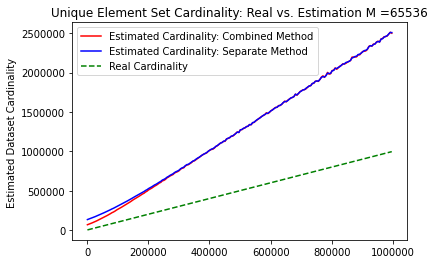

Difference Factor Is: 0.4
 
Combined Method Report
Correcting Alpha = 0.4003278784107557
Standard Error = 51122.733
Error Percentage = 10.255%
 
Separate Method Report
Correcting Alpha = 0.4081368281735311
Standard Error = 50158.797
Error Percentage = 10.062%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.4,5000,1000,1000000,1,1,1)

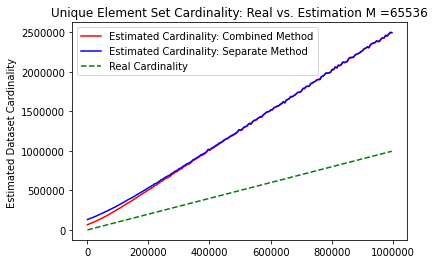

Difference Factor Is: 0.25
 
Combined Method Report
Correcting Alpha = 0.40004038511050694
Standard Error = 51159.684
Error Percentage = 10.263%
 
Separate Method Report
Correcting Alpha = 0.408939556755769
Standard Error = 50057.03
Error Percentage = 10.042%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.25,5000,1000,1000000,1,1,1)

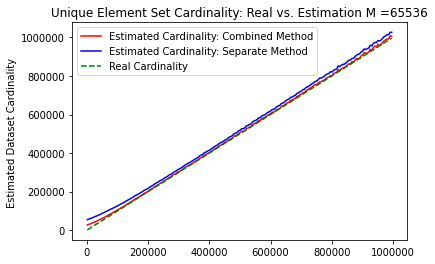

Difference Factor Is: 0.25
 
Combined Method Report
Correcting Alpha = 1.0003257471176565
Standard Error = 20458.935
Error Percentage = 4.104%
 
Separate Method Report
Correcting Alpha = 1.0006682575652326
Standard Error = 20456.398
Error Percentage = 4.104%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.25,5000,1000,1000000,1,0.408939556755769,0.40004038511050694)

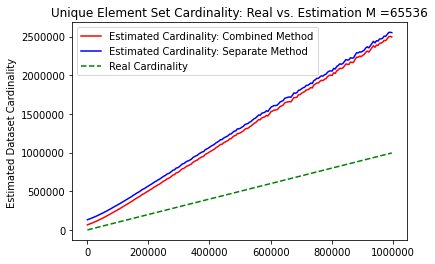

Difference Factor Is: 0.01
 
Combined Method Report
Correcting Alpha = 0.40023994264786933
Standard Error = 51133.93
Error Percentage = 10.258%
 
Separate Method Report
Correcting Alpha = 0.40193830516051865
Standard Error = 50917.94
Error Percentage = 10.214%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.01,5000,1000,1000000,1,1,1)

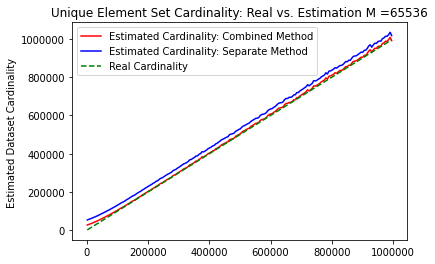

Difference Factor Is: 0.01
 
Combined Method Report
Correcting Alpha = 0.9980000105238734
Standard Error = 20506.943
Error Percentage = 4.114%
 
Separate Method Report
Correcting Alpha = 0.9981431042177923
Standard Error = 20504.027
Error Percentage = 4.113%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.01,5000,1000,1000000,1,0.40193830516051865,0.40023994264786933)

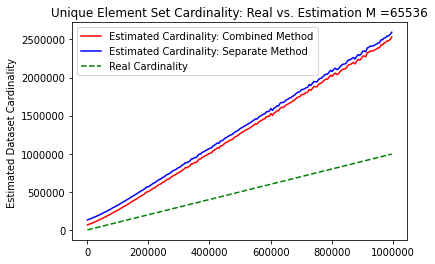

Difference Factor Is: 0.001
 
Combined Method Report
Correcting Alpha = 0.3998255587206559
Standard Error = 51187.54
Error Percentage = 10.268%
 
Separate Method Report
Correcting Alpha = 0.4000028445233407
Standard Error = 51164.845
Error Percentage = 10.264%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.001,5000,1000,1000000,1,1,1)

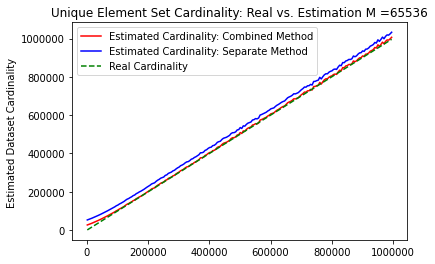

Difference Factor Is: 0.001
 
Combined Method Report
Correcting Alpha = 1.0002150140452968
Standard Error = 20461.479
Error Percentage = 4.105%
 
Separate Method Report
Correcting Alpha = 1.0002399201444336
Standard Error = 20460.968
Error Percentage = 4.105%


In [ ]:
plot_graph_loglog_disjoint_dif(16,0.001,5000,1000,1000000,1,0.4000028445233407,0.3998255587206559)